In [1]:
import numpy as np
import torch # needs to be imported before deepSSF stuff or kernel crashes for some reason
import matplotlib.pyplot as plt

from movebench.lib.deepSSF.deepSSF_model import ModelParams, ConvJointModel, Params_to_Grid_Block

In [2]:
# set up extension to chipdataset
from movebench import Study

study_id = "tsavo_lions"
config_path = "../configs/layers_all.yaml"
split = "train"  # or "test"

study = Study(study_id)
plan = study.layer_plan(config_path)

In [3]:
ds = study.chip_dataset(split='train',
                        mode='steps',
                        config=config_path)

/data/vision/beery/scratch/justin/movebench/movebench/trajectories.py:105: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df["valid_step"].shift(-1).fillna(False).astype(bool)


In [4]:
from torch.utils.data import Dataset, DataLoader        # Dataset and batch data loading
from movebench.datasets.chips import ChipDataset

# class buffalo_data(Dataset):

#     def __init__(self):
#         # data loading. Here we are just using the combined_stack as the spatial covariates
#         self.spatial_data_x = combined_stack

#         # the scalar data that will be converted to spatial data and added as channels to the spatial covariates
#         self.scalar_to_grid_data = torch.from_numpy(buffalo_df[['hour_t2_sin',
#                                                                 'hour_t2_cos',
#                                                                 'yday_t2_sin',
#                                                                 'yday_t2_cos']].values).float()

#         # the bearing data that will be added as a channel to the spatial covariates
#         self.bearing_x = torch.from_numpy(buffalo_df[['bearing_tm1']].values).float()

#         # the target data
#         self.target = torch.tensor(pres_stack)

#         # number of samples
#         self.n_samples = self.spatial_data_x.shape[0]

#     def __len__(self):
#         # allows for the use of len() function
#         return self.n_samples

#     def __getitem__(self, index):
#         # allows for indexing of the dataset
#         return self.spatial_data_x[index], self.scalar_to_grid_data[index], self.bearing_x[index], self.target[index]

import pandas as pd
import math

from movebench.trajectories import select_step_starts

class deepSSFDataset(Dataset):
    
    def __init__(self, chip_dataset): # hacky constructor
        super().__init__()
        self.chip_dataset = chip_dataset
        
        steps = select_step_starts(self.chip_dataset.df)  # same defaults as ChipDataset step filtering
        bearing_north0 = steps["start_bearing"].to_numpy(dtype=float)  # MoveBench: 0=north, +pi/2=east

        # deepSSF: 0=east, +pi/2=north
        bearing_east0 = (math.pi / 2) - bearing_north0
        bearing_east0 = (bearing_east0 + math.pi) % (2 * math.pi) - math.pi  # wrap to [-pi, pi]

        self.bearing_x = torch.tensor(bearing_east0, dtype=torch.float32)

    def __len__(self):
        return len(self.chip_dataset)

    def __getitem__(self, idx):
        # environment rasters
        spatial_data_x, valid_mask, target, xfm, crs = self.chip_dataset[idx]
        # print(spatial_data_x.shape, valid_mask.shape)

        # time
        row = self.chip_dataset._rows[int(idx)]
        ts = pd.to_datetime(row.timestamp, utc=True)
        doy = int(ts.dayofyear)
        hour_frac = float(ts.hour) + float(ts.minute) / 60.0 + float(ts.second) / 3600.0
        sin_doy = math.sin(2.0 * math.pi * float(doy) / 365.25)
        cos_doy = math.cos(2.0 * math.pi * float(doy) / 365.25)
        sin_tod = math.sin(2.0 * math.pi * hour_frac / 24.0)
        cos_tod = math.cos(2.0 * math.pi * hour_frac / 24.0)
        scalar_to_grid_data = torch.tensor([sin_tod, cos_tod, sin_doy, cos_doy])

        return spatial_data_x, scalar_to_grid_data, self.bearing_x[idx].unsqueeze(0), target

In [6]:
dataset_train = deepSSFDataset(ds)
spatial_data_x, scalar_to_grid_data, bearing_x, target = dataset_train[100]

spatial_data_x, scalar_to_grid_data, bearing_x, target

/data/vision/beery/scratch/justin/movebench/movebench/trajectories.py:105: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df["valid_step"].shift(-1).fillna(False).astype(bool)


(tensor([[[-0.0937, -0.0937, -0.0937,  ...,  0.0986,  0.4540,  0.4540],
          [-0.4388, -0.4388, -0.4388,  ...,  0.5270,  0.4168,  0.4168],
          [-0.8531, -0.4447, -0.4393,  ...,  0.5275,  0.4168,  0.4168],
          ...,
          [ 0.0818,  0.0818, -0.1314,  ...,  0.0000,  0.0000,  0.0000],
          [-0.0987, -0.0987, -0.1214,  ...,  0.0000,  0.0000,  0.0000],
          [-0.1202, -0.1202, -0.1202,  ...,  0.0000,  0.0000,  0.0000]],
 
         [[-0.1678, -0.1678, -0.1678,  ..., -0.2113,  0.1087,  0.1087],
          [-0.3748, -0.3748, -0.3748,  ...,  0.0162,  0.0166,  0.0166],
          [-0.4671, -0.3763, -0.3751,  ...,  0.0165,  0.0165,  0.0165],
          ...,
          [-1.0662, -1.0662, -0.4129,  ..., -0.7776, -0.6976, -0.6976],
          [-1.1280, -1.1280, -1.0583,  ..., -0.7557, -0.6668, -0.6668],
          [-1.1354, -1.1354, -1.1354,  ..., -0.7531, -0.6631, -0.6631]],
 
         [[-0.3998, -0.5962, -0.9332,  ...,  0.0055,  0.0769,  0.5853],
          [ 0.3491,  0.1911,

In [7]:
spatial_data_x.shape

torch.Size([94, 101, 101])

In [25]:
batch_size = 32
n_max_pool_layers = 2 # used to determine the number of inputs entering the fully connected block - needs to be manually changed if the number of max pooling layers is changed
device='cpu'

# Create an instance of the ModelParams class using the params_dict
params = ModelParams({"batch_size": 32, #number of samples in each batch
               "image_dim": 101, #number of pixels along the edge of each local patch/image
               "pixel_size": 25, #number of metres along the edge of a pixel
               "dim_in_nonspatial_to_grid": 4, #the number of scalar predictors that are converted to a grid and appended to the spatial features
               "dense_dim_in_nonspatial": 4, #change this to however many other scalar predictors you have (bearing, velocity etc)
               "dense_dim_hidden": 128, #number of nodes in the hidden layers
               "dense_dim_out": 128, #number of nodes in the output of the fully connected block (FCN)
               
               "dense_dim_in_all": 576, #2500,# + 128, #number of inputs entering the fully connected block once the nonspatial features have been concatenated to the spatial features
               
               "input_channels": 94 + 4, #53 + 4, #number of spatial layers in each image + number of scalar layers that are converted to a grid
               
               "output_channels": 4, #number of filters to learn
               "kernel_size": 3, #the size of the 2D moving windows / kernels that are being learned
               "stride": 1, #the stride used when applying the kernel.  This reduces the dimension of the output if set to greater than 1
               "kernel_size_mp": 2, #the size of the kernel that is used in max pooling operations
               "stride_mp": 2, #the stride that is used in max pooling operations
               "padding": 1, #the amount of padding to apply to images prior to applying the 2D convolution
               "num_movement_params": 12, #number of parameters used to parameterise the movement kernel
               "dropout": 0.1, #the proportion of nodes that are dropped out in the dropout layers
               "device": device
               })

# Create an instance of the ConvJointModel class using the params
model = ConvJointModel(params).to(device)

# Print the model architecture to check that it worked
print(model)

ConvJointModel(
  (scalar_grid_output): Scalar_to_Grid_Block()
  (conv_habitat): Conv2d_block_spatial(
    (conv2d): Sequential(
      (0): Conv2d(98, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(4, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU()
      (4): Conv2d(4, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): ReLU()
      (6): Conv2d(4, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
  )
  (conv_movement): Conv2d_block_toFC(
    (conv2d): Sequential(
      (0): Conv2d(98, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Conv2d(4, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (6): Conv2d(4, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (7

In [26]:
ds_test = study.chip_dataset(split='test',
                        mode='steps',
                        config=config_path)
dataset_test = deepSSFDataset(ds_test)

/data/vision/beery/scratch/justin/movebench/movebench/trajectories.py:105: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df["valid_step"].shift(-1).fillna(False).astype(bool)
/data/vision/beery/scratch/justin/movebench/movebench/trajectories.py:105: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df["valid_step"].shift(-1).fillna(False).astype(bool)


In [27]:
batch_size = 32
dataloader_train = DataLoader(dataset=dataset_train,
                              batch_size=batch_size,
                              shuffle=True)
dataloader_val = DataLoader(dataset=dataset_test,
                            batch_size=batch_size,
                            shuffle=False)

In [28]:
# Number of samples in the train dataset
print("Number of samples in the train dataset: ", len(dataloader_train.dataset))
print('\n')

# Select an index from the test dataset to retrieve a sample, between 0 and number of samples
# We picked this fairly arbitrarily, but with some interesting environmental features to illustrate the model's predictions
iteration_index = 20

# 2. Retrieve a single sample (features and label) from the test dataset at the specified index

# sample_spatial_covs is a sample of the spatial covariates for a single step
# sample_temporal_covs is a sample of the temporal covariates for a single step
# sample_prev_bearing is a sample bearing of the previous step
# sample_next_step is the target label (what we are trying to predict) for the next step

# We set these here and will also use them later in the script to check how the model's predictions look,
# and when we extract feature maps from the convolutional layers
sample_spatial_covs, sample_temporal_covs, sample_prev_bearing, sample_next_step = dataloader_train.dataset[iteration_index]

# 3. Reshape data tensors to add a batch dimension (since the model expects batches)
sample_spatial_covs = sample_spatial_covs.unsqueeze(0).to(device)
sample_temporal_covs = sample_temporal_covs.unsqueeze(0).to(device)
sample_prev_bearing = sample_prev_bearing.unsqueeze(0).to(device)
sample_next_step = sample_next_step.unsqueeze(0).to(device)

print(f'Shape of the sample spatial covariates:  {sample_spatial_covs.shape}')
print(f'Shape of the sample temporal covariates: {sample_temporal_covs.shape}')
print(f'Shape of the sample previous bearing:    {sample_prev_bearing.shape}')
print(f'Shape of the sample next step:           {sample_next_step.shape}')

Number of samples in the train dataset:  1294


Shape of the sample spatial covariates:  torch.Size([1, 94, 101, 101])
Shape of the sample temporal covariates: torch.Size([1, 4])
Shape of the sample previous bearing:    torch.Size([1, 1])
Shape of the sample next step:           torch.Size([1, 101, 101])


In [29]:
def recover_hour(sin_term, cos_term):
    # Calculate the angle theta
    theta = np.arctan2(sin_term, cos_term)
    # Calculate hour_t2
    hour = (12 * theta) / np.pi % 24
    return hour

def recover_yday(sin_term, cos_term):
    # Calculate the angle theta
    theta = np.arctan2(sin_term, cos_term)
    # Calculate hour_t2
    yday = (365 * theta) / (2 * np.pi)  % 365
    return yday

# Convert the PyTorch tensor x2 to a NumPy array:
#   1) Detach from the computation graph so no gradients are tracked.
#   2) Move to CPU memory.
#   3) Convert to NumPy.
# Then extract the first sample (index 0) and its respective channel for each variable:
hour_t2_sin = sample_temporal_covs.detach().cpu().numpy()[0, 0]
hour_t2_cos = sample_temporal_covs.detach().cpu().numpy()[0, 1]
yday_t2_sin = sample_temporal_covs.detach().cpu().numpy()[0, 2]
yday_t2_cos = sample_temporal_covs.detach().cpu().numpy()[0, 3]

# Convert x3 similarly and extract the bearing from the first sample and channel:
bearing = sample_prev_bearing.detach().cpu().numpy()[0]

hour_t2 = recover_hour(hour_t2_sin, hour_t2_cos)
hour_t2_integer = int(hour_t2)  # Convert to integer
print(f'Hour:               {hour_t2_integer}')

yday_t2 = recover_yday(yday_t2_sin, yday_t2_cos)
yday_t2_integer = int(yday_t2)  # Convert to integer
print(f'Day of the year:    {yday_t2_integer}')

bearing_degrees = np.degrees(bearing) % 360
# bearing_degrees = round(bearing_degrees, 1)  # Round to 2 decimal places
# bearing_degrees = int(bearing_degrees)  # Convert to integer
print(f'Bearing (radians):  {bearing}')
print(f'Bearing (degrees):  {bearing_degrees}')

Hour:               12
Day of the year:    175
Bearing (radians):  [1.5707964]
Bearing (degrees):  [90.]


In [30]:
# 1. NDVI (Normalized Difference Vegetation Index)
ndvi_natural = sample_spatial_covs.detach().cpu()[0, 0, :, :]
# ndvi_natural = (ndvi_norm * (ndvi_max - ndvi_min)) + ndvi_min

# 2. Canopy cover
canopy_natural = sample_spatial_covs.detach().cpu()[0, 1, :, :]
# canopy_natural = (canopy_norm * (canopy_max - canopy_min)) + canopy_min

# 3. Herbaceous vegetation
herby_natural = sample_spatial_covs.detach().cpu()[0, 2, :, :]
# herby_natural = (herby_norm * (herby_max - herby_min)) + herby_min

# 4. Slope
slope_natural = sample_spatial_covs.detach().cpu()[0, 3, :, :]
# slope_natural = (slope_norm * (slope_max - slope_min)) + slope_min

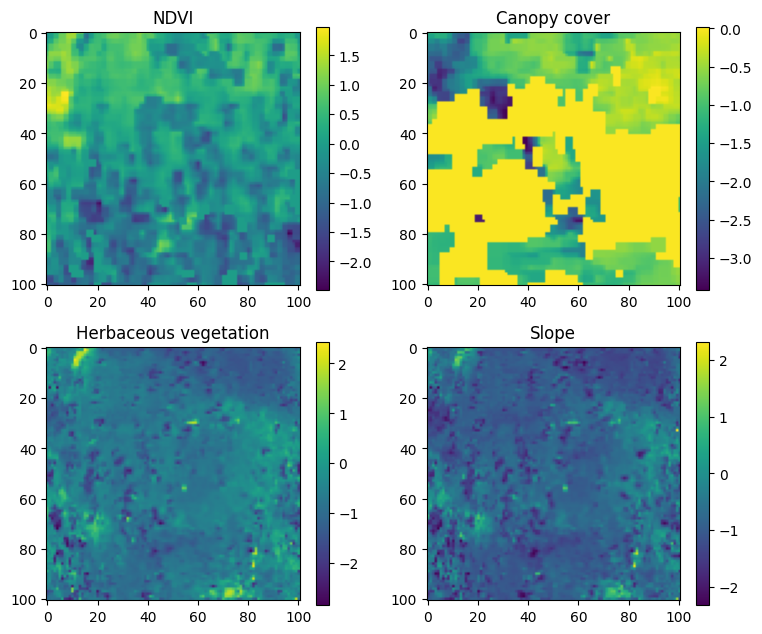

In [31]:
# Plot the covariates
fig, axs = plt.subplots(2, 2, figsize=(9, 7.5))

# Plot NDVI
im1 = axs[0, 0].imshow(ndvi_natural.numpy(), cmap='viridis')
axs[0, 0].set_title('NDVI')
fig.colorbar(im1, ax=axs[0, 0])

# Plot Canopy cover
im2 = axs[0, 1].imshow(canopy_natural.numpy(), cmap='viridis')
axs[0, 1].set_title('Canopy cover')
fig.colorbar(im2, ax=axs[0, 1])

# Plot Herbaceous vegetation
im3 = axs[1, 0].imshow(herby_natural.numpy(), cmap='viridis')
axs[1, 0].set_title('Herbaceous vegetation')
fig.colorbar(im3, ax=axs[1, 0])

# Plot Slope
im4 = axs[1, 1].imshow(slope_natural.numpy(), cmap='viridis')
axs[1, 1].set_title('Slope')
fig.colorbar(im4, ax=axs[1, 1])


In [32]:
model.eval()
test = model((sample_spatial_covs, sample_temporal_covs, sample_prev_bearing))

In [33]:
sample_prev_bearing.shape

torch.Size([1, 1])

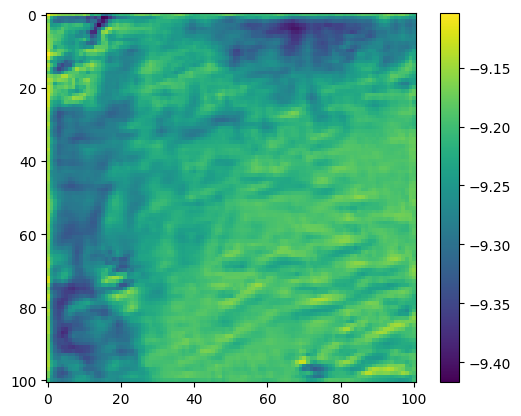

In [34]:
plt.imshow(test.detach().cpu().numpy()[0,:,:,0])
plt.colorbar()
plt.show()

Bearing (radians): [1.5707964]
Bearing (degrees): [90.]


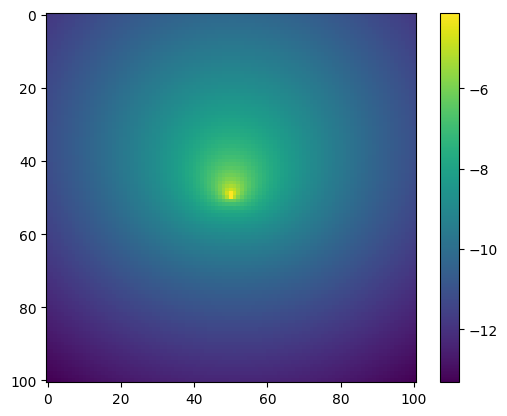

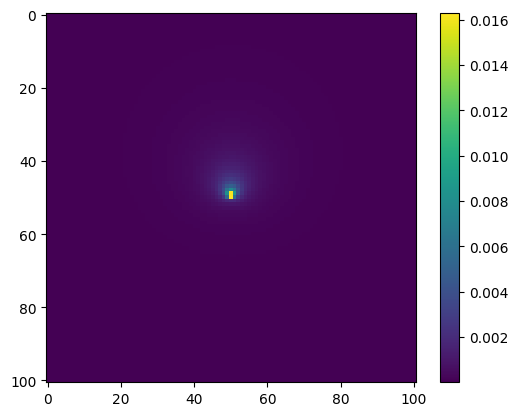

In [35]:
# Print input bearing
print(f'Bearing (radians): {bearing}')
print(f'Bearing (degrees): {bearing_degrees}')

# Plot the movement density on the log-scale
plt.imshow(test.detach().cpu().numpy()[0,:,:,1])
plt.colorbar()
plt.show()

# Plot the movement density on the natural scale
plt.imshow(np.exp(test.detach().cpu().numpy()[0,:,:,1]))
plt.colorbar()
plt.show()

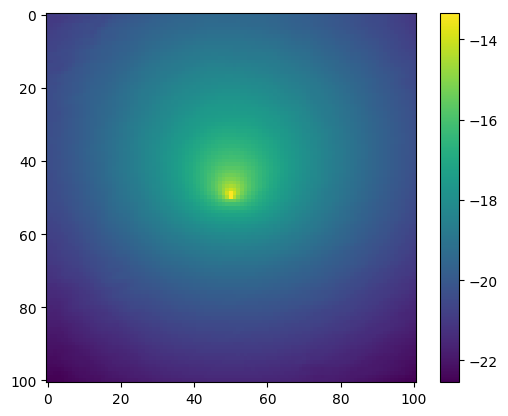

In [36]:
# Combine the habitat selection and the movement probabilities (unnormalised)
next_step = (test[:, :, :, 0] + test[:, :, :, 1])

# Plot the combined output
plt.imshow(next_step.detach().cpu().numpy()[0,:,:])
plt.colorbar()
plt.show()

In [37]:
import torch.nn as nn

class negativeLogLikeLoss(nn.Module):
    """
    Custom negative log-likelihood loss that operates on a 4D prediction tensor
    (batch, height, width, channels). The forward pass:
    1. Sums across channel 3 (two log-densities, habitat selection and movement predictions) to obtain a combined log-density.
    2. Multiplies this log-density by the target, which is 0 everywhere except for at the location of the next step, effectively extracting that value,
    then multiplies by -1 such that the function can be minimised (and the probabilities maximised).
    3. Applies the user-specified reduction (mean, sum, or none).
    """

    def __init__(self, reduction='mean'):
        """
        Args:
            reduction (str): Specifies the reduction to apply to the output:
                             'mean', 'sum', or 'none'.
        """
        super(negativeLogLikeLoss, self).__init__()
        assert reduction in ['mean', 'sum', 'none'], \
            "reduction should be 'mean', 'sum', or 'none'"
        self.reduction = reduction

    def forward(self, predict, target):
        """
        Forward pass of the negative log-likelihood loss.

        Args:
            predict (Tensor): A tensor of shape (B, H, W, 2) with log-densities
                              across two channels to be summed.
            target  (Tensor): A tensor of the same spatial dimensions (B, H, W)
                              indicating where the log-densities should be evaluated.

        Returns:
            Tensor: The computed negative log-likelihood loss. Shape depends on
                    the reduction method.
        """

        habitat_probability_surface = predict[:, :, :, 0] 
        movement_probability_surface = predict[:, :, :, 1] 

        # Sum the log-densities from the two channels
        predict_prod = habitat_probability_surface + movement_probability_surface

        # Check for NaNs in the combined predictions
        if torch.isnan(predict_prod).any():
            print("NaNs detected in predict_prod")
            print("predict_prod:", predict_prod)
            raise ValueError("NaNs detected in predict_prod")

        # Normalise the next-step log-densities using the log-sum-exp trick
        # predict_prod = predict_prod - torch.logsumexp(predict_prod, dim = (1, 2), keepdim = True)

        # Compute negative log-likelihood by multiplying log-densities with target
        # and then flipping the sign
        negLogLike = -1 * (predict_prod * target)

        # Check for NaNs after computing negative log-likelihood
        if torch.isnan(negLogLike).any():
            print("NaNs detected in negLogLike")
            print("negLogLike:", negLogLike)
            raise ValueError("NaNs detected in negLogLike")

        # Just extract the value at the next step
        negLogLike = negLogLike.sum(dim=(1, 2))

        # Calculate the loss on the habitat selection surface
        habitat_loss = -1 * (habitat_probability_surface * target)
        habitat_loss = habitat_loss.sum(dim=(1, 2))

        # Calculate the loss on the movement surface
        movement_loss = -1 * (movement_probability_surface * target)
        movement_loss = movement_loss.sum(dim=(1, 2))

        # Apply the specified reduction
        if self.reduction == 'mean':
            return torch.mean(negLogLike), torch.mean(habitat_loss), torch.mean(movement_loss)
        elif self.reduction == 'sum':
            return torch.sum(negLogLike), torch.sum(habitat_loss), torch.sum(movement_loss)
        elif self.reduction == 'none':
            return negLogLike, habitat_loss, movement_loss

        # Default return (though it should never reach here without hitting an if)
        return negLogLike, habitat_loss, movement_loss


In [38]:
# Define the negative log-likelihood loss function with mean reduction
loss_fn = negativeLogLikeLoss(reduction='mean')

# Calculate the loss using the model outputs and the targets
total_loss, habitat_loss, movement_loss = loss_fn(model((sample_spatial_covs, sample_temporal_covs, sample_prev_bearing)), sample_next_step)
print(f'Total loss:     {total_loss}')
print(f'Habitat loss:   {habitat_loss}')
print(f'Movement loss:  {movement_loss}')

Total loss:     18.490795135498047
Habitat loss:   9.237203598022461
Movement loss:  9.253591537475586


In [39]:
class EarlyStopping:
    def __init__(self, patience=5, verbose=False, delta=0, path='checkpoint.pt', trace_func=print):
        """
        Args:
            patience (int): How long to wait after last time validation loss improved.
                            Default: 5
            verbose (bool): If True, prints a message for each validation loss improvement.
                            Default: False
            delta (float): Minimum change in the monitored quantity to qualify as an improvement.
                            Default: 0
            path (str): Path for the checkpoint to be saved to.
                            Default: 'checkpoint.pt'
            trace_func (function): trace print function.
                            Default: print
        """

        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = float('inf')
        self.delta = delta
        self.path = path
        self.trace_func = trace_func

    def __call__(self, val_loss, model):

        # takes the validation loss and the model as inputs
        score = -val_loss

        # save the model's weights if the validation loss decreases
        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)

        # if the validation loss does not decrease, increment the counter
        elif score < self.best_score + self.delta:
            self.counter += 1
            self.trace_func(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        '''Saves model when validation loss decrease.'''
        if self.verbose:
            self.trace_func(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}).  Saving model ...')
        torch.save(model.state_dict(), self.path)
        self.val_loss_min = val_loss

In [40]:
path_save_weights = f'checkpoint_deepSSF_lions.pt'
print(path_save_weights)

checkpoint_deepSSF_lions.pt


In [41]:
# Set the initial learning rates for each process
initial_learning_rate_movement = 1e-5
initial_learning_rate_habitat = 1e-4

In [42]:
import torch.optim as optim

# Define the negative log-likelihood loss function with mean reduction
loss_fn = negativeLogLikeLoss(reduction='mean')

# Create a combined optimiser for all movement-related parameters
movement_params = list(model.conv_movement.parameters()) + list(model.fcn_movement_all.parameters())

# Define separate optimizers for each component
optimiser_movement = optim.Adam(movement_params, lr=initial_learning_rate_movement)
optimiser_habitat = optim.Adam(model.conv_habitat.parameters(), lr=initial_learning_rate_habitat)

# Put optimisers into a tuple to call in the training loop
optimisers = (optimiser_movement, optimiser_habitat)

# Create separate schedulers for each optimizer
scheduler_movement = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimiser_movement, 'min', factor=0.1, patience=5)
scheduler_habitat = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimiser_habitat, 'min', factor=0.1, patience=5)

# EarlyStopping stops training after 'patience=10' epochs with no improvement,
#    optionally saving the best model weights
early_stopping = EarlyStopping(patience=25, verbose=True, path=path_save_weights)

In [43]:
def train_loop(dataloader_train, model, loss_fn, optimisers, skip_epoch0_training=False):
    """
    Runs the training process for one epoch using the given dataloader, model,
    loss function, and optimizer. Prints progress updates every few batches.
    """

    # Unpack optimisers
    optimiser_movement, optimiser_habitat = optimisers

    # 1. Total number of training examples
    num_train_batches = len(dataloader_train)
    size = len(dataloader_train.dataset)

    # 2. Put model in training mode (affects layers like dropout, batchnorm)
    model.train()

    # 3. Variable to accumulate the total loss over the epoch
    epoch_loss = 0.0

    # 4. Loop over batches in the training dataloader
    for batch, (x1, x2, x3, y) in enumerate(dataloader_train):

        # Move the batch of data to the specified device (CPU/GPU)
        x1 = x1.to(device)
        x2 = x2.to(device)
        x3 = x3.to(device)
        y = y.to(device)

        # Forward pass: compute the model output and loss
        with torch.set_grad_enabled(not skip_epoch0_training):
            outputs = model((x1, x2, x3))
            total_loss, habitat_loss, movement_loss = loss_fn(outputs, y)

        epoch_loss += total_loss.detach()  # Use detach to prevent memory leaks

        # Only perform optimization if not skipping training
        if not skip_epoch0_training:
            # Backpropagation: compute gradients and update parameters
            # Reset gradients before the next iteration

            # Zero all gradients
            optimiser_movement.zero_grad()
            optimiser_habitat.zero_grad()

            # Single backward pass on total loss
            total_loss.backward()

            # For movement optimizer: save habitat gradients, then zero them out
            habitat_grads = []
            for param in model.conv_habitat.parameters():
                # Save the gradient
                if param.grad is not None:
                    habitat_grads.append(param.grad.clone())
                else:
                    habitat_grads.append(None)
                # Zero out habitat gradient for movement update
                param.grad = None

            # Update movement parameters
            optimiser_movement.step()

            # For habitat optimizer: restore habitat gradients and zero movement gradients
            for param in model.conv_movement.parameters():
                param.grad = None
            for param in model.fcn_movement_all.parameters():
                param.grad = None

            # Restore habitat gradients
            for i, param in enumerate(model.conv_habitat.parameters()):
                param.grad = habitat_grads[i]

            # Update habitat parameters
            optimiser_habitat.step()

        # Print an update every 5 batches to keep track of training progress
        if batch % 20 == 0:
            loss_val = total_loss.item()
            current = batch * batch_size + len(x1)
            if skip_epoch0_training:
                print(f"[Observation only] loss: {loss_val:>15f}  [{current:>5d}/{size:>5d}]")
            else:
                print(f"loss: {loss_val:>15f}  [{current:>5d}/{size:>5d}]")

        torch.cuda.empty_cache()

    # Compute the average training loss and print it
    epoch_loss /= num_train_batches
    if skip_epoch0_training:
        print(f"\nAvg training loss (observation only): {epoch_loss:>15f}")
    else:
        print(f"\nAvg training loss: {epoch_loss:>15f}")
    train_losses.append(epoch_loss.item())

In [44]:
def test_loop(dataloader_test, model, loss_fn):
    """
    Evaluates the model on the provided test dataset by computing
    the average loss over all batches.
    No gradients are computed during this process (torch.no_grad()).
    """

    # 1. Set the model to evaluation mode (affects layers like dropout, batchnorm).
    model.eval()

    size = len(dataloader_test.dataset)
    num_batches = len(dataloader_test)

    test_loss = 0

    # 2. Disable gradient computation to speed up evaluation and reduce memory usage
    with torch.no_grad():
        # 3. Loop through each batch in the test dataloader
        for x1, x2, x3, y in dataloader_test:

            # Move the batch of data to the appropriate device (CPU/GPU)
            # x1, x2, x3 are the spatial covariates, temporal covariates, and bearing, respectively
            # y is the label (observed location of the next step)
            x1 = x1.to(device)
            x2 = x2.to(device)
            x3 = x3.to(device)
            y = y.to(device)

            # Compute the loss on the test set (no backward pass needed)
            total_loss, habitat_loss, movement_loss = loss_fn(model((x1, x2, x3)), y)
            test_loss += total_loss.detach()

    # 4. Compute average test loss over all batches
    test_loss /= num_batches

    torch.cuda.empty_cache()

    # Print the average test loss
    print(f"Avg test loss:    {test_loss:>15f} \n")

In [ ]:
import os

epochs = 120
train_losses = []  # Track training losses across epochs
val_losses = []   # Track validation losses across epochs
val_habitat_losses = []  # Track validation habitat losses across epochs
val_movement_losses = []  # Track validation movement losses across epochs

# Define the negative log-likelihood loss function with mean reduction
loss_fn = negativeLogLikeLoss(reduction='mean') #, alpha=0.5

# Set the initial learning rates for each process
initial_learning_rate_movement = 1e-5
initial_learning_rate_habitat = 1e-4

# Create a combined optimiser for all movement-related parameters
movement_params = list(model.conv_movement.parameters()) + list(model.fcn_movement_all.parameters())

# Define separate optimizers for each component
optimiser_movement = optim.Adam(movement_params, lr=initial_learning_rate_movement)
optimiser_habitat = optim.Adam(model.conv_habitat.parameters(), lr=initial_learning_rate_habitat)

# Put optimisers into a tuple to call in the training loop
optimisers = (optimiser_movement, optimiser_habitat)

# Create separate schedulers for each optimizer
scheduler_movement = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimiser_movement, 'min', factor=0.1, patience=5)
scheduler_habitat = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimiser_habitat, 'min', factor=0.1, patience=5)

# Reinitialise early stopping
early_stopping = EarlyStopping(patience=10, verbose=True, path=path_save_weights)

# Create directory for saving training images
os.makedirs(f'deepssf_training_images', exist_ok=True)

for t in range(epochs):

    # Initialise variables to store during training
    train_loss = 0.0
    num_train_batches = len(dataloader_train)

    val_loss = 0.0
    val_loss_habitat = 0.0
    val_loss_movement = 0.0
    num_batches = len(dataloader_val)

    print(f"Epoch {t+1}\n-------------------------------")

    # Skip training in the first epoch, but still calculate losses
    skip_training = (t == 0)

    # 1. Run the training loop for one epoch using the training dataloader
    train_loop(dataloader_train, model, loss_fn, optimisers, skip_epoch0_training=skip_training)

    # 2. Evaluate model performance on the validation dataset
    model.eval()  # Switch to evaluation mode for proper layer behavior
    with torch.no_grad():

        # Loop through each batch in the validation dataloader
        for x1, x2, x3, y in dataloader_val:
            # Move data to the chosen device (CPU/GPU)
            x1 = x1.to(device)
            x2 = x2.to(device)
            x3 = x3.to(device)
            y = y.to(device)

            # Accumulate validation loss
            total_loss, habitat_loss, movement_loss = loss_fn(model((x1, x2, x3)), y)
            val_loss += total_loss.detach()
            val_loss_habitat += habitat_loss.detach()
            val_loss_movement += movement_loss.detach()

    # # 3. Step the scheduler based on the validation loss (adjusts learning rate if needed)
    # scheduler.step(val_loss)
    scheduler_movement.step(val_loss_movement)
    scheduler_habitat.step(val_loss_habitat)

    # 4. Compute the average validation loss and print it, along with the current learning rate
    val_loss /= num_batches
    val_loss_habitat /= num_batches
    val_loss_movement /= num_batches

    print(f"Avg validation loss:            {val_loss:>15f}")
    print(f"Avg validation habitat loss:    {val_loss_habitat:>15f}")
    print(f"Avg validation movement loss:   {val_loss_movement:>15f}")
    print(f"Movement learning rate:         {scheduler_movement.get_last_lr()}")
    print(f"Habitat learning rate:          {scheduler_habitat.get_last_lr()}")

    # 5. Track the validation loss for plotting or monitoring
    val_losses.append(val_loss.item())
    val_habitat_losses.append(val_loss_habitat.item())
    val_movement_losses.append(val_loss_movement.item())

    # Memory management - add after validation but before early stopping check
    # torch.cuda.empty_cache()
    # gc.collect()

    # 6. Early stopping: if no improvement in validation loss for a set patience, stop training
    early_stopping(val_loss, model)
    if early_stopping.early_stop:
        print("Early stopping")
        # Restore the best model weights saved by EarlyStopping
        model.load_state_dict(torch.load(path_save_weights, weights_only=True, map_location=device))
        test_loop(dataloader_test, model, loss_fn)  # Evaluate on test set once training stops
        break
    else:
        model.eval()
        print("\n")

    torch.cuda.empty_cache()


    # ----------------------------------------------------
    # The following code demonstrates how
    # to optionally visualize or save intermediate results
    # (e.g., habitat probability surface, movement probability,
    # and next-step probability surfaces).

    # uncomment the code all in one go to run it (it should be inside the training loop)
    # ----------------------------------------------------

    # Extract training and validation losses for plotting

    # Convert the list of tensors to a single tensor
    train_losses_np = torch.tensor(train_losses).detach().cpu().numpy()
    val_losses_np = torch.tensor(val_losses).detach().cpu().numpy()
    val_habitat_losses_np = torch.tensor(val_habitat_losses).detach().cpu().numpy()
    val_movement_losses_np = torch.tensor(val_movement_losses).detach().cpu().numpy()

    # Number of epochs
    n_epochs = len(val_losses)

    # -----------------------------------------------------------
    # 1. Retrieve a single test example (covariates and labels)
    #    at the specified 'iteration_index' from the test dataset
    # -----------------------------------------------------------
    x1, x2, x3, labels = dataloader_train.dataset[iteration_index]

    # -----------------------------------------------------------
    # 2. Add a batch dimension and move tensors to the device
    #    for model inference
    # -----------------------------------------------------------
    x1 = x1.unsqueeze(0).to(device)
    x2 = x2.unsqueeze(0).to(device)
    x3 = x3.unsqueeze(0).to(device)

    # -----------------------------------------------------------
    # 3. Run the model on the single test example
    # -----------------------------------------------------------
    test = model((x1, x2, x3))

    # -----------------------------------------------------------
    # 4. Extract habitat and movement outputs;
    #    convert them to NumPy arrays for visualization
    # -----------------------------------------------------------
    hab_density = test.detach().cpu().numpy()[0, :, :, 0]
    movement_density = test.detach().cpu().numpy()[0, :, :, 1]

    # -----------------------------------------------------------
    # 5. Generate masks to exclude certain border cells for
    #    color scale reasons (setting them to -inf).
    # -----------------------------------------------------------
    x_mask = np.ones_like(hab_density)
    y_mask = np.ones_like(hab_density)

    # Mask out a few columns (0-2 and 98-end) and rows (0-2 and 98-end)
    x_mask[:, :3] = -np.inf
    x_mask[:, 98:] = -np.inf
    y_mask[:3, :] = -np.inf
    y_mask[98:, :] = -np.inf

    # Apply the masks to habitat density
    hab_density_mask = hab_density * x_mask * y_mask

    # Combine habitat and movement densities to represent
    # next-step probability
    step_density = hab_density + movement_density
    step_density_mask = step_density * x_mask * y_mask

    # Plot the covariates
    fig, axs = plt.subplots(2, 2, figsize=(9, 7.5))

    # # Plot NDVI
    # im1 = axs[0, 0].imshow(ndvi_natural.numpy(), cmap='viridis')
    # axs[0, 0].set_title('NDVI')
    # fig.colorbar(im1, ax=axs[0, 0])

    # Plot Training and Validation Loss
    axs[0, 0].plot(range(n_epochs), train_losses_np, label='Training Loss', color='blue')
    axs[0, 0].plot(range(n_epochs), val_losses_np, label='Validation Loss', color='red')
    # axs[0, 0].plot(range(n_epochs), val_habitat_losses_np, label='Validation Habitat Loss', color='green')
    # axs[0, 0].plot(range(n_epochs), val_movement_losses_np, label='Validation Movement Loss', color='orange')
    axs[0, 0].set_xlim(0, 120)
    axs[0, 0].set_title('Training and validation loss')
    axs[0, 0].set_xlabel('Epoch')
    axs[0, 0].set_ylabel('Loss')
    axs[0, 0].legend()

    # Plot habitat selection log-probability
    im2 = axs[0, 1].imshow(hab_density_mask, cmap='viridis')
    axs[0, 1].set_title('Habitat log-probability')
    fig.colorbar(im2, ax=axs[0, 1])

    # Plot movement log-probability
    im3 = axs[1, 0].imshow(movement_density, cmap='viridis')
    axs[1, 0].set_title('Movement log-probability')
    fig.colorbar(im3, ax=axs[1, 0])

    # Plot next-step log-probability
    im4 = axs[1, 1].imshow(step_density_mask, cmap='viridis')
    axs[1, 1].set_title('Next-step log-probability')
    fig.colorbar(im4, ax=axs[1, 1])

    filename_covs = f'training_epoch{t}_yday{yday_t2_integer}_hour{hour_t2_integer}_bearing{bearing_degrees}.png'
    plt.tight_layout()
    plt.savefig(filename_covs, dpi=300) # creates inconsistent image sizes >>> , bbox_inches='tight'
    # plt.show()
    plt.close()  # Close the figure to free memory

print("Done!")

Epoch 1
-------------------------------
[Observation only] loss:       15.229621  [   32/ 1294]


KeyboardInterrupt: 

Exception ignored in: 'rasterio._env.log_error'
Traceback (most recent call last):
  File "/data/vision/beery/scratch/justin/envs/movement/lib/python3.11/logging/__init__.py", line 1544, in log
    def log(self, level, msg, *args, **kwargs):

KeyboardInterrupt: 


torch.Size([1, 101, 101, 2])


NameError: name 'output_dir' is not defined

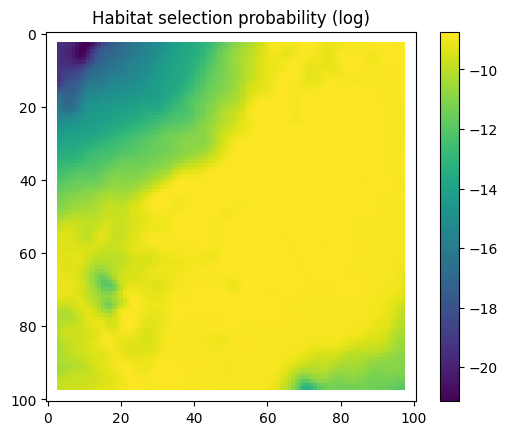

In [ ]:
# -------------------------------------------------------------------------
# Switch the model to evaluation mode (e.g., disables dropout, etc.)
# -------------------------------------------------------------------------
model.eval()

# -------------------------------------------------------------------------
# Pass the inputs through the model; 'test' will have shape [batch, H, W, 2]
# -------------------------------------------------------------------------
test = model((sample_spatial_covs, sample_temporal_covs, sample_prev_bearing))
# test = model((x1, x2, x3))
print(test.shape)

# -------------------------------------------------------------------------
# Extract and exponentiate the habitat density channel
#    (at index 0 in the last dimension)
# -------------------------------------------------------------------------
hab_density = test.detach().cpu().numpy()[0, :, :, 0]
hab_density_exp = np.exp(hab_density)
# print(np.sum(hab_density_exp))  # Debug: check the sum of exponentiated values

# -------------------------------------------------------------------------
# Create masks to remove unwanted edge cells from visualization
#    (setting them to -∞ affects the color scale in plots)
# -------------------------------------------------------------------------
x_mask = np.ones_like(hab_density)
y_mask = np.ones_like(hab_density)

x_mask[:, :3] = -np.inf
x_mask[:, 98:] = -np.inf
y_mask[:3, :] = -np.inf
y_mask[98:, :] = -np.inf

# -------------------------------------------------------------------------
# Apply the masks to the habitat density (log scale) and exponentiated version
# -------------------------------------------------------------------------
hab_density_mask = hab_density * x_mask * y_mask
hab_density_exp_mask = hab_density_exp * x_mask * y_mask

# -------------------------------------------------------------------------
# Plot and save the habitat density in log scale
# -------------------------------------------------------------------------
plt.imshow(hab_density_mask)
plt.colorbar()
plt.title('Habitat selection probability (log)')
plt.savefig(f'{output_dir}/hab_log_prob_id{buffalo_id}.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# -------------------------------------------------------------------------
# Plot and save the habitat density in probability (exponentiated) scale
# -------------------------------------------------------------------------
plt.imshow(hab_density_exp_mask)
plt.colorbar()
plt.title('Habitat selection probability')
plt.savefig(f'{output_dir}/hab_prob_id{buffalo_id}.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# -------------------------------------------------------------------------
# Extract and exponentiate the movement density channel
#    (at index 1 in the last dimension)
# -------------------------------------------------------------------------
move_density = test.detach().cpu().numpy()[0, :, :, 1]
move_density_exp = np.exp(move_density)
# print(np.sum(move_density_exp))  # Debug: check the sum of exponentiated values

# -------------------------------------------------------------------------
# Apply the same masking strategy to movement densities
# -------------------------------------------------------------------------
move_density_mask = move_density * x_mask * y_mask
move_density_exp_mask = move_density_exp * x_mask * y_mask

# -------------------------------------------------------------------------
# Plot and save the movement density in log scale
# -------------------------------------------------------------------------
plt.imshow(move_density_mask)
plt.colorbar()
plt.title('Movement probability (log)')
plt.savefig(f'{output_dir}/move_log_prob_id{buffalo_id}.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# -------------------------------------------------------------------------
# Plot and save the movement density in probability (exponentiated) scale
# -------------------------------------------------------------------------
plt.imshow(move_density_exp_mask)
plt.colorbar()
plt.title('Movement probability')
plt.savefig(f'{output_dir}/move_prob_id{buffalo_id}.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# -------------------------------------------------------------------------
# Compute the next-step density by adding habitat + movement (log-space)
#     Then exponentiate and normalize
# -------------------------------------------------------------------------
step_density = test[0, :, :, 0] + test[0, :, :, 1]
step_density = step_density.detach().cpu().numpy()
step_density_exp = np.exp(step_density)
# print('Sum of step density exp = ', np.sum(step_density_exp))  # Debug

step_density_exp_norm = step_density_exp / np.sum(step_density_exp)
# print('Sum of step density exp norm = ', np.sum(step_density_exp_norm))  # Debug

# -------------------------------------------------------------------------
# Apply masks to the step densities (log and exponentiated + normalized)
# -------------------------------------------------------------------------
step_density_mask = step_density * x_mask * y_mask
step_density_exp_norm_mask = step_density_exp_norm * x_mask * y_mask

# -------------------------------------------------------------------------
# Plot and save the combined next-step probability surface in log scale
# -------------------------------------------------------------------------
plt.imshow(step_density_mask)
plt.colorbar()
plt.title('Next-step probability (log)')
# plt.savefig(f'{output_dir}/step_log_prob_id{buffalo_id}.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# -------------------------------------------------------------------------
# Plot and save the combined next-step probability surface in probability scale
# -------------------------------------------------------------------------
plt.imshow(step_density_exp_norm_mask)
plt.colorbar()
plt.title('Next-step probability')
# plt.savefig(f'{output_dir}/step_prob_id{buffalo_id}.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()


In [ ]:
torch.cuda.empty_cache()

# -------------------------------------------------------------------------
# Create a list to store the intermediate output from the fully connected
#    movement sub-network (fcn_movement_all)
# -------------------------------------------------------------------------
intermediate_output = []

def hook(module, input, output):
    """
    Hook function that captures the output of the specified layer
    (fcn_movement_all) during the forward pass.
    """
    intermediate_output.append(output)

# -------------------------------------------------------------------------
# Register the forward hook on 'fcn_movement_all', so its outputs
#    are recorded every time the model does a forward pass.
# -------------------------------------------------------------------------
hook_handle = model.fcn_movement_all.register_forward_hook(hook)

# -------------------------------------------------------------------------
# Perform a forward pass with the model in evaluation mode,
#    disabling gradient computation.
# -------------------------------------------------------------------------
model.eval()
with torch.no_grad():
    final_output = model((sample_spatial_covs, sample_temporal_covs, sample_prev_bearing))

# -------------------------------------------------------------------------
# Inspect the captured intermediate output
#    'intermediate_output[0]' corresponds to the first (and only) forward pass.
# -------------------------------------------------------------------------
print("Intermediate output shape:", intermediate_output[0].shape)
print("Intermediate output values:", intermediate_output[0][0])

# -------------------------------------------------------------------------
# Remove the hook to avoid repeated capturing in subsequent passes
# -------------------------------------------------------------------------
hook_handle.remove()

# -------------------------------------------------------------------------
# Unpack the parameters from the FCN output (assumes a specific ordering)
# -------------------------------------------------------------------------
gamma_shape1, gamma_scale1, gamma_weight1, \
gamma_shape2, gamma_scale2, gamma_weight2, \
vonmises_mu1, vonmises_kappa1, vonmises_weight1, \
vonmises_mu2, vonmises_kappa2, vonmises_weight2 = intermediate_output[0][0]

# -------------------------------------------------------------------------
# Convert parameters from log-space (if applicable) and print them
#    Gamma and von Mises parameters
# -------------------------------------------------------------------------
# --- Gamma #1 ---
print("Gamma shape 1:", torch.exp(gamma_shape1))
print("Gamma scale 1:", torch.exp(gamma_scale1))
print("Gamma weight 1:",
      torch.exp(gamma_weight1) / (torch.exp(gamma_weight1) + torch.exp(gamma_weight2)))

# --- Gamma #2 ---
print("Gamma shape 2:", torch.exp(gamma_shape2))
print("Gamma scale 2:", torch.exp(gamma_scale2) * 500)  # scale factor 500
print("Gamma weight 2:",
      torch.exp(gamma_weight2) / (torch.exp(gamma_weight1) + torch.exp(gamma_weight2)))

# --- von Mises #1 ---
# % (2*np.pi) ensures the mu (angle) is wrapped within [0, 2π)
print("Von Mises mu 1:", vonmises_mu1 % (2*np.pi))
print("Von Mises kappa 1:", torch.exp(vonmises_kappa1))
print("Von Mises weight 1:",
      torch.exp(vonmises_weight1) / (torch.exp(vonmises_weight1) + torch.exp(vonmises_weight2)))

# --- von Mises #2 ---
print("Von Mises mu 2:", vonmises_mu2 % (2*np.pi))
print("Von Mises kappa 2:", torch.exp(vonmises_kappa2))
print("Von Mises weight 2:",
      torch.exp(vonmises_weight2) / (torch.exp(vonmises_weight1) + torch.exp(vonmises_weight2)))


Intermediate output shape: torch.Size([1, 12])
Intermediate output values: tensor([ 0.1581,  0.0689, -0.1109, -0.4343, -0.3105, -0.1050, -0.0209, -0.0971,
         0.0767, -0.1672, -0.0959, -0.0342])
Gamma shape 1: tensor(1.1713)
Gamma scale 1: tensor(1.0714)
Gamma weight 1: tensor(0.4985)
Gamma shape 2: tensor(0.6477)
Gamma scale 2: tensor(366.5497)
Gamma weight 2: tensor(0.5015)
Von Mises mu 1: tensor(6.2623)
Von Mises kappa 1: tensor(0.9074)
Von Mises weight 1: tensor(0.5277)
Von Mises mu 2: tensor(6.1160)
Von Mises kappa 2: tensor(0.9086)
Von Mises weight 2: tensor(0.4723)


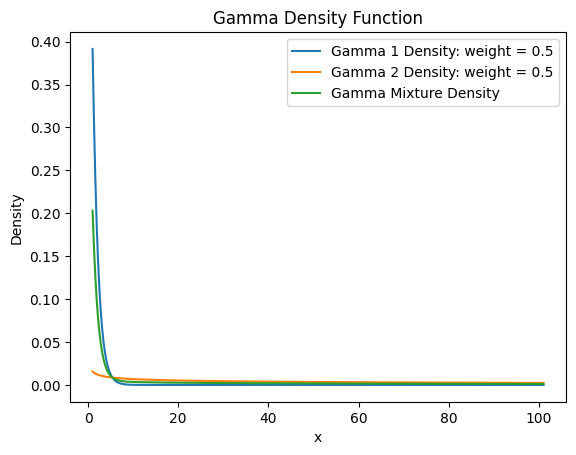

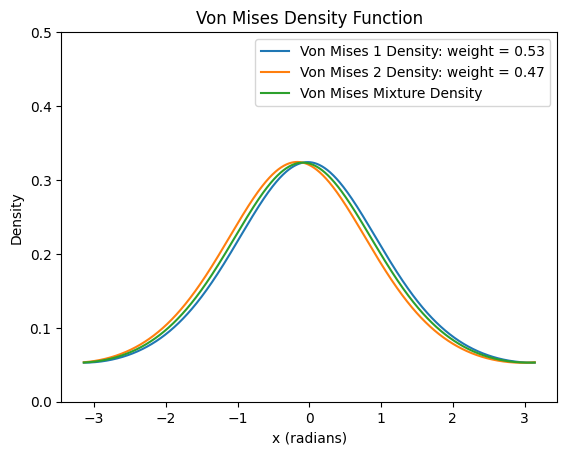

In [ ]:
# -------------------------------------------------------------------------
# Define helper functions for calculating Gamma and von Mises log-densities
# -------------------------------------------------------------------------
def gamma_density(x, shape, scale):
    """
    Computes the log of the Gamma density for each value in x.

    Args:
      x (Tensor): Input values for which to compute the density.
      shape (float): Gamma shape parameter
      scale (float): Gamma scale parameter

    Returns:
      Tensor: The log of the Gamma probability density at each x.
    """
    return -1*torch.lgamma(shape) - shape*torch.log(scale) \
           + (shape - 1)*torch.log(x) - x/scale

def vonmises_density(x, kappa, vm_mu):
    """
    Computes the log of the von Mises density for each value in x.

    Args:
      x (Tensor): Input angles in radians.
      kappa (float): Concentration parameter (kappa)
      vm_mu (float): Mean direction parameter (mu)

    Returns:
      Tensor: The log of the von Mises probability density at each x.
    """
    return kappa*torch.cos(x - vm_mu) - 1*(np.log(2*torch.pi) + torch.log(torch.special.i0(kappa)))


# -------------------------------------------------------------------------
# Round and display the mixture weights for the Gamma distributions
# -------------------------------------------------------------------------
gamma_weight1_recovered = torch.exp(gamma_weight1)/(torch.exp(gamma_weight1) + torch.exp(gamma_weight2))
rounded_gamma_weight1 = round(gamma_weight1_recovered.item(), 2)

gamma_weight2_recovered = torch.exp(gamma_weight2)/(torch.exp(gamma_weight1) + torch.exp(gamma_weight2))
rounded_gamma_weight2 = round(gamma_weight2_recovered.item(), 2)

# -------------------------------------------------------------------------
# Round and display the mixture weights for the von Mises distributions
# -------------------------------------------------------------------------
vonmises_weight1_recovered = torch.exp(vonmises_weight1)/(torch.exp(vonmises_weight1) + torch.exp(vonmises_weight2))
rounded_vm_weight1 = round(vonmises_weight1_recovered.item(), 2)

vonmises_weight2_recovered = torch.exp(vonmises_weight2)/(torch.exp(vonmises_weight1) + torch.exp(vonmises_weight2))
rounded_vm_weight2 = round(vonmises_weight2_recovered.item(), 2)


# -------------------------------------------------------------------------
# 1. Plotting the Gamma mixture distribution
#    a) Generate x values
#    b) Compute individual Gamma log densities
#    c) Exponentiate and combine using recovered weights
# -------------------------------------------------------------------------
x_values = torch.linspace(1, 101, 1000).to(device)
gamma1_density = gamma_density(x_values, torch.exp(gamma_shape1), torch.exp(gamma_scale1))
gamma2_density = gamma_density(x_values, torch.exp(gamma_shape2), torch.exp(gamma_scale2)*500)
gamma_mixture_density = gamma_weight1_recovered*torch.exp(gamma1_density) \
                        + gamma_weight2_recovered*torch.exp(gamma2_density)

# Move results to CPU and convert to NumPy for plotting
x_values_np = x_values.cpu().numpy()
gamma1_density_np = np.exp(gamma1_density.cpu().numpy())
gamma2_density_np = np.exp(gamma2_density.cpu().numpy())
gamma_mixture_density_np = gamma_mixture_density.cpu().numpy()

# -------------------------------------------------------------------------
# 2. Plot the Gamma distributions and their mixture
# -------------------------------------------------------------------------
# filename_gamma_distributions = f'{output_dir}/id{buffalo_id}_gamma_distributions.png'

plt.plot(x_values_np, gamma1_density_np, label=f'Gamma 1 Density: weight = {rounded_gamma_weight1}')
plt.plot(x_values_np, gamma2_density_np, label=f'Gamma 2 Density: weight = {rounded_gamma_weight2}')
plt.plot(x_values_np, gamma_mixture_density_np, label='Gamma Mixture Density')
plt.xlabel('x')
plt.ylabel('Density')
plt.title('Gamma Density Function')
plt.legend()
# plt.savefig(filename_gamma_distributions, dpi=300, bbox_inches='tight')
plt.show()


# -------------------------------------------------------------------------
# 3. Plotting the von Mises mixture distribution
#    a) Generate x values from -π to π
#    b) Compute individual von Mises log densities
#    c) Exponentiate and combine using recovered weights
# -------------------------------------------------------------------------
x_values = torch.linspace(-np.pi, np.pi, 1000).to(device)
vonmises1_density = vonmises_density(x_values, torch.exp(vonmises_kappa1), vonmises_mu1)
vonmises2_density = vonmises_density(x_values, torch.exp(vonmises_kappa2), vonmises_mu2)
vonmises_mixture_density = vonmises_weight1_recovered*torch.exp(vonmises1_density) \
                           + vonmises_weight2_recovered*torch.exp(vonmises2_density)

# Move results to CPU and convert to NumPy for plotting
x_values_np = x_values.cpu().numpy()
vonmises1_density_np = np.exp(vonmises1_density.cpu().numpy())
vonmises2_density_np = np.exp(vonmises2_density.cpu().numpy())
vonmises_mixture_density_np = vonmises_mixture_density.cpu().numpy()

# -------------------------------------------------------------------------
# 4. Plot the von Mises distributions and their mixture
# -------------------------------------------------------------------------
# filename_vonmises_distributions = f'{output_dir}/id{buffalo_id}_vonmises_distributions.png'

plt.plot(x_values_np, vonmises1_density_np, label=f'Von Mises 1 Density: weight = {rounded_vm_weight1}')
plt.plot(x_values_np, vonmises2_density_np, label=f'Von Mises 2 Density: weight = {rounded_vm_weight2}')
plt.plot(x_values_np, vonmises_mixture_density_np, label='Von Mises Mixture Density')
plt.xlabel('x (radians)')
plt.ylabel('Density')
plt.title('Von Mises Density Function')
plt.ylim(0, 0.5)  # Set a limit for the y-axis
plt.legend()
# plt.savefig(filename_vonmises_distributions, dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# To use all of the test samples
print(f'There are {len(dataset_test)} samples in the test dataset')
bs = len(dataset_test) # batch size
dataloader_test = DataLoader(dataset=dataset_test, batch_size=bs, shuffle=True)

torch.cuda.empty_cache()

There are 815 samples in the test dataset


In [ ]:
# -----------------------------------------------------------
# Fetch a batch of data from the training dataloader
# -----------------------------------------------------------
x1_batch, x2_batch, x3_batch, labels = next(iter(dataloader_test))

# Move the input batches to the same device as the model
x1_batch = x1_batch.to(device)
x2_batch = x2_batch.to(device)
x3_batch = x3_batch.to(device)

# -----------------------------------------------------------
# Register a forward hook to capture the outputs
#    from 'fcn_movement_all' during the forward pass
# -----------------------------------------------------------
hook_handle = model.fcn_movement_all.register_forward_hook(hook)

# -----------------------------------------------------------
# Perform a forward pass in evaluation mode to generate
#    and capture the sub-network's outputs in 'intermediate_output'
# -----------------------------------------------------------
model.eval()  # Disables certain layers like dropout

# Pass the batch through the model
final_output = model((x1_batch, x2_batch, x3_batch))

# -----------------------------------------------------------
# Prepare lists to store the distribution parameters
#    for each sample in the batch
# -----------------------------------------------------------
gamma_shape1_list = []
gamma_scale1_list = []
gamma_weight1_list = []
gamma_shape2_list = []
gamma_scale2_list = []
gamma_weight2_list = []
vonmises_mu1_list = []
vonmises_kappa1_list = []
vonmises_weight1_list = []
vonmises_mu2_list = []
vonmises_kappa2_list = []
vonmises_weight2_list = []

# -----------------------------------------------------------
# Extract parameters from 'intermediate_output'
#    for every sample in the batch
# -----------------------------------------------------------
for batch_output in intermediate_output:
    # Each 'batch_output' corresponds to one forward pass;
    # it might contain multiple samples if the batch size > 1
    for sample_output in batch_output:
        # Unpack the 12 parameters of the Gamma and von Mises mixtures
        gamma_shape1, gamma_scale1, gamma_weight1, \
        gamma_shape2, gamma_scale2, gamma_weight2, \
        vonmises_mu1, vonmises_kappa1, vonmises_weight1, \
        vonmises_mu2, vonmises_kappa2, vonmises_weight2 = sample_output

        # Convert log-space parameters to real space, then store
        gamma_shape1_list.append(torch.exp(gamma_shape1).item())
        gamma_scale1_list.append(torch.exp(gamma_scale1).item())
        gamma_weight1_list.append(
            (torch.exp(gamma_weight1)/(torch.exp(gamma_weight1) + torch.exp(gamma_weight2))).item()
        )
        gamma_shape2_list.append(torch.exp(gamma_shape2).item())
        gamma_scale2_list.append((torch.exp(gamma_scale2)*500).item())  # scale factor 500
        gamma_weight2_list.append(
            (torch.exp(gamma_weight2)/(torch.exp(gamma_weight1) + torch.exp(gamma_weight2))).item()
        )
        vonmises_mu1_list.append((vonmises_mu1 % (2*np.pi)).item())
        vonmises_kappa1_list.append(torch.exp(vonmises_kappa1).item())
        vonmises_weight1_list.append(
            (torch.exp(vonmises_weight1)/(torch.exp(vonmises_weight1) + torch.exp(vonmises_weight2))).item()
        )
        vonmises_mu2_list.append((vonmises_mu2 % (2*np.pi)).item())
        vonmises_kappa2_list.append(torch.exp(vonmises_kappa2).item())
        vonmises_weight2_list.append(
            (torch.exp(vonmises_weight2)/(torch.exp(vonmises_weight1) + torch.exp(vonmises_weight2))).item()
        )


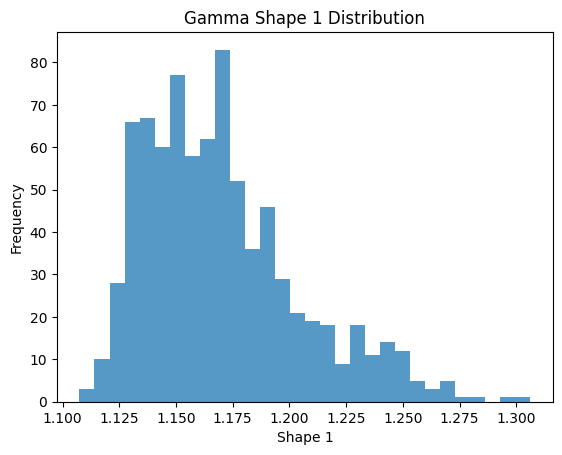

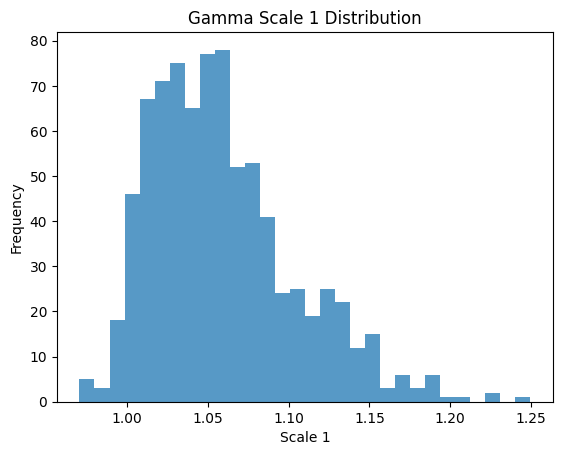

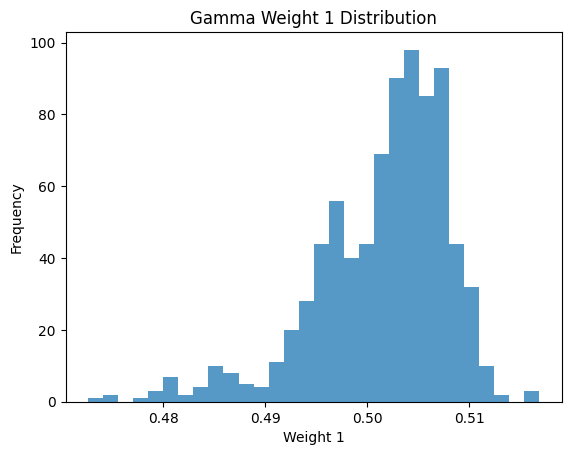

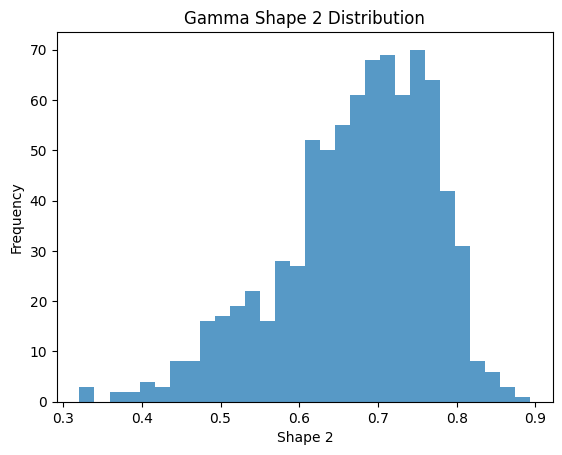

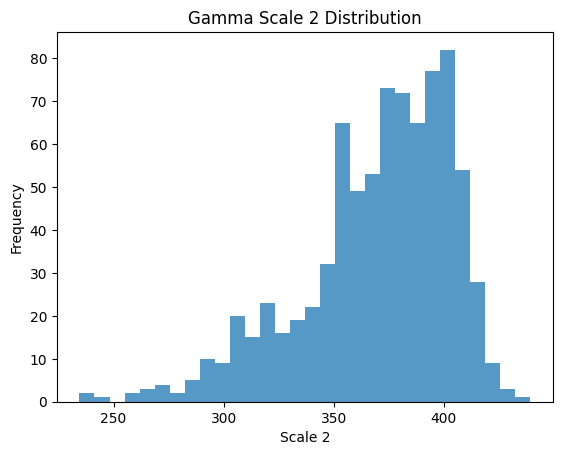

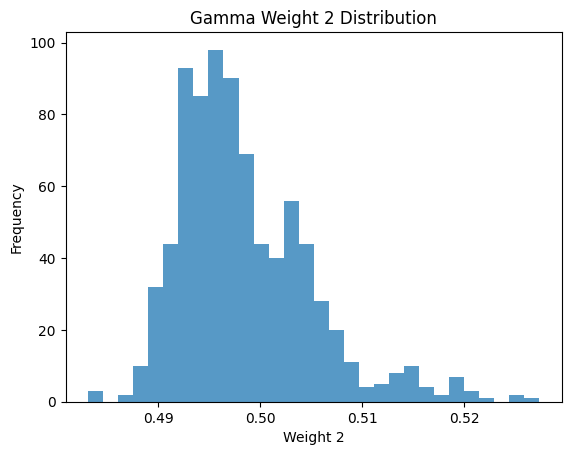

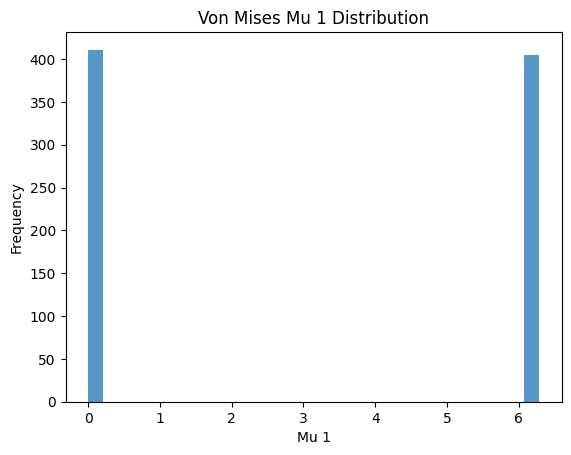

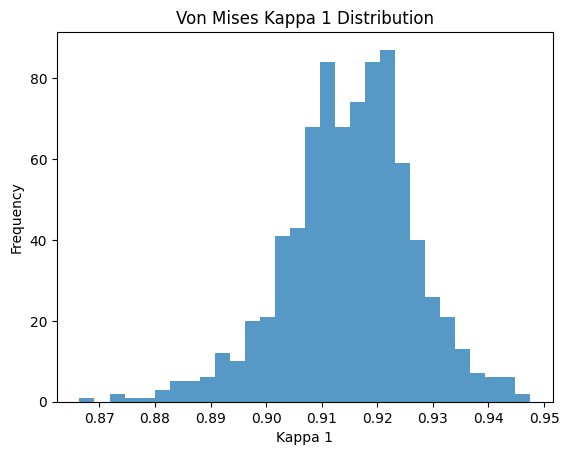

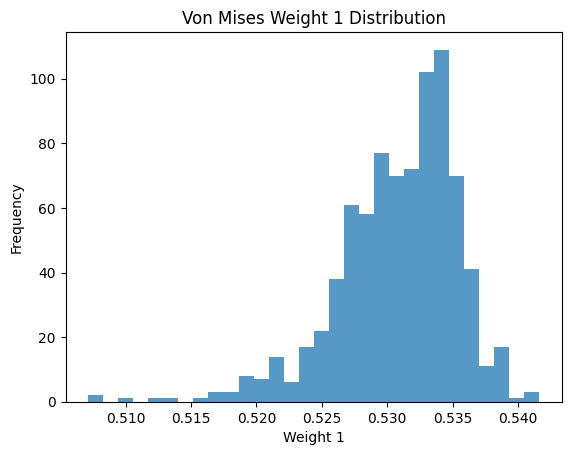

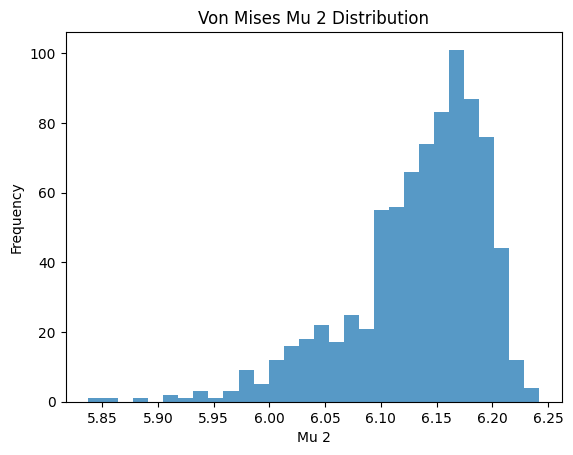

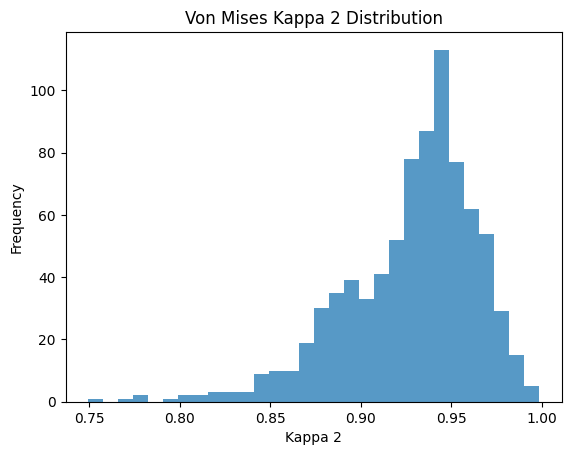

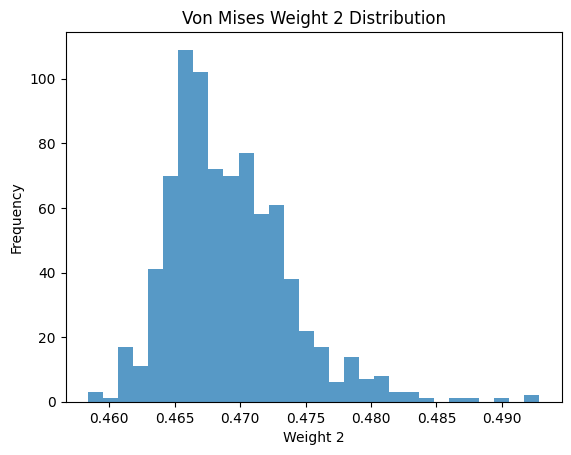

In [ ]:
# -----------------------------------------------------------
# Define a helper function to plot histograms
#    for the collected parameters
# -----------------------------------------------------------
def plot_histogram(data, title, xlabel):
    """
    Plots a histogram of the provided data.

    Args:
        data (list): Data points to plot in a histogram.
        title (str): Title of the histogram plot.
        xlabel (str): X-axis label.
    """
    plt.figure()
    plt.hist(data, bins=30, alpha=0.75)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel('Frequency')

    # Generate a filename from the title (replace spaces with underscores)
    filename = title.replace(' ', '_') + '.png'
    # filepath = os.path.join(output_dir, filename)

    # Save the figure
    # plt.savefig(filepath, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()  # Close the figure to free memory\

# -----------------------------------------------------------
# Plot histograms for each parameter distribution
# -----------------------------------------------------------
plot_histogram(gamma_shape1_list, 'Gamma Shape 1 Distribution', 'Shape 1')
plot_histogram(gamma_scale1_list, 'Gamma Scale 1 Distribution', 'Scale 1')
plot_histogram(gamma_weight1_list, 'Gamma Weight 1 Distribution', 'Weight 1')
plot_histogram(gamma_shape2_list, 'Gamma Shape 2 Distribution', 'Shape 2')
plot_histogram(gamma_scale2_list, 'Gamma Scale 2 Distribution', 'Scale 2')
plot_histogram(gamma_weight2_list, 'Gamma Weight 2 Distribution', 'Weight 2')
plot_histogram(vonmises_mu1_list, 'Von Mises Mu 1 Distribution', 'Mu 1')
plot_histogram(vonmises_kappa1_list, 'Von Mises Kappa 1 Distribution', 'Kappa 1')
plot_histogram(vonmises_weight1_list, 'Von Mises Weight 1 Distribution', 'Weight 1')
plot_histogram(vonmises_mu2_list, 'Von Mises Mu 2 Distribution', 'Mu 2')
plot_histogram(vonmises_kappa2_list, 'Von Mises Kappa 2 Distribution', 'Kappa 2')
plot_histogram(vonmises_weight2_list, 'Von Mises Weight 2 Distribution', 'Weight 2')

# -----------------------------------------------------------
# Remove the hook to stop capturing outputs
#    in subsequent forward passes
# -----------------------------------------------------------
hook_handle.remove()